# Bank Account Fraud (BAF) - Exploratory Data Analysis

Steps covered in this notebook:

1. **Load data** - read `Base.csv` (~1M applications, one row per application, target `fraud_bool`).
2. **Initial inspection** - preview rows, dtypes, summary statistics and null counts.
3. **Preprocessing** - negative values in six columns are missing-value codes; they are replaced with `NaN` and a `<col>_missing_flag` indicator is added. String columns are cast to `category`.
4. **Feature types** - split columns into continuous, discrete and categorical.
5. **Fraud rate by month** - check how the fraud rate moves over the 8 months, which motivates a time-based split.
6. **Train split** - months 0-6 are used for EDA; month 7 is held out for validation and not looked at here.
7. **Columns to remove** - compare fraud rate by value for the constant column and every missing-value flag to decide what to drop.
8. **Kept features** - compare fraud vs non-fraud distributions for every kept feature, grouped by how each will be treated in feature engineering.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plot

## Load Data

In [2]:
df = pd.read_csv("../data/Base.csv")

## Initial Inspection

In [3]:
df.head()

,fraud_bool,income,name_email_similarity,prev_address_months_count,current_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,zip_count_4w,velocity_6h,velocity_24h,velocity_4w,bank_branch_count_8w,date_of_birth_distinct_emails_4w,employment_status,credit_risk_score,email_is_free,housing_status,phone_home_valid,phone_mobile_valid,bank_months_count,has_other_cards,proposed_credit_limit,foreign_request,source,session_length_in_minutes,device_os,keep_alive_session,device_distinct_emails_8w,device_fraud_count,month
0,0,0.3,0.986506,-1,25,40,0.006735,102.453711,AA,1059,13096.035018,7850.955007,6742.080561,5,5,CB,163,1,BC,0,1,9,0,1500.0,0,INTERNET,16.224843,linux,1,1,0,0
1,0,0.8,0.617426,-1,89,20,0.010095,-0.849551,AD,1658,9223.283431,5745.251481,5941.664859,3,18,CA,154,1,BC,1,1,2,0,1500.0,0,INTERNET,3.363854,other,1,1,0,0
2,0,0.8,0.996707,9,14,40,0.012316,-1.490386,AB,1095,4471.472149,5471.988958,5992.555113,15,11,CA,89,1,BC,0,1,30,0,200.0,0,INTERNET,22.730559,windows,0,1,0,0
3,0,0.6,0.475100,11,14,30,0.006991,-1.863101,AB,3483,14431.993621,6755.344479,5970.336831,11,13,CA,90,1,BC,0,1,1,0,200.0,0,INTERNET,15.215816,linux,1,1,0,0
4,0,0.9,0.842307,-1,29,40,5.742626,47.152498,AA,2339,7601.511579,5124.046930,5940.734212,1,6,CA,91,0,BC,1,1,26,0,200.0,0,INTERNET,3.743048,other,0,1,0,0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 32 columns):
 #   Column                            Non-Null Count    Dtype  
---  ------                            --------------    -----  
 0   fraud_bool                        1000000 non-null  int64  
 1   income                            1000000 non-null  float64
 2   name_email_similarity             1000000 non-null  float64
 3   prev_address_months_count         1000000 non-null  int64  
 4   current_address_months_count      1000000 non-null  int64  
 5   customer_age                      1000000 non-null  int64  
 6   days_since_request                1000000 non-null  float64
 7   intended_balcon_amount            1000000 non-null  float64
 8   payment_type                      1000000 non-null  object 
 9   zip_count_4w                      1000000 non-null  int64  
 10  velocity_6h                       1000000 non-null  float64
 11  velocity_24h                      1000

In [5]:
df.describe(include="all")

,fraud_bool,income,name_email_similarity,prev_address_months_count,current_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,zip_count_4w,velocity_6h,velocity_24h,velocity_4w,bank_branch_count_8w,date_of_birth_distinct_emails_4w,employment_status,credit_risk_score,email_is_free,housing_status,phone_home_valid,phone_mobile_valid,bank_months_count,has_other_cards,proposed_credit_limit,foreign_request,source,session_length_in_minutes,device_os,keep_alive_session,device_distinct_emails_8w,device_fraud_count,month
count,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1.000000e+06,1000000.000000,1000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000,1000000.000000,1000000.000000,1000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000,1000000.000000,1000000,1000000.000000,1000000.000000,1000000.0,1000000.000000
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5,NaN,NaN,NaN,NaN,NaN,NaN,7,NaN,NaN,7,NaN,NaN,NaN,NaN,NaN,NaN,2,NaN,5,NaN,NaN,NaN,NaN
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,AB,NaN,NaN,NaN,NaN,NaN,NaN,CA,NaN,NaN,BC,NaN,NaN,NaN,NaN,NaN,NaN,INTERNET,NaN,other,NaN,NaN,NaN,NaN
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,370554,NaN,NaN,NaN,NaN,NaN,NaN,730252,NaN,NaN,372143,NaN,NaN,NaN,NaN,NaN,NaN,992952,NaN,342728,NaN,NaN,NaN,NaN
mean,0.011029,0.562696,0.493694,16.718568,86.587867,33.689080,1.025705e+00,8.661499,NaN,1572.692049,5665.296605,4769.781965,4856.324016,184.361849,9.503544,NaN,130.989595,0.529886,NaN,0.417077,0.889676,10.839303,0.222988,515.851010,0.025242,NaN,7.544940,NaN,0.576947,1.018312,0.0,3.288674
std,0.104438,0.290343,0.289125,44.046230,88.406599,12.025799,5.381835e+00,20.236155,NaN,1005.374565,3009.380665,1479.212612,919.843934,459.625329,5.033792,NaN,69.681812,0.499106,NaN,0.493076,0.313293,12.116875,0.416251,487.559902,0.156859,NaN,8.033106,NaN,0.494044,0.180761,0.0,2.209994
min,0.000000,0.100000,0.000001,-1.000000,-1.000000,10.000000,4.036860e-09,-15.530555,NaN,1.000000,-170.603072,1300.307314,2825.748405,0.000000,0.000000,NaN,-170.000000,0.000000,NaN,0.000000,0.000000,-1.000000,0.000000,190.000000,0.000000,NaN,-1.000000,NaN,0.000000,-1.000000,0.0,0.000000
25%,0.000000,0.300000,0.225216,-1.000000,19.000000,20.000000,7.193246e-03,-1.181488,NaN,894.000000,3436.365848,3593.179135,4268.368423,1.000000,6.000000,NaN,83.000000,0.000000,NaN,0.000000,1.000000,-1.000000,0.000000,200.000000,0.000000,NaN,3.103053,NaN,0.000000,1.000000,0.0,1.000000
50%,0.000000,0.600000,0.492153,-1.000000,52.000000,30.000000,1.517574e-02,-0.830507,NaN,1263.000000,5319.769349,4749.921161,4913.436941,9.000000,9.000000,NaN,122.000000,1.000000,NaN,0.000000,1.000000,5.000000,0.000000,200.000000,0.000000,NaN,5.114321,NaN,1.000000,1.000000,0.0,3.000000
75%,0.000000,0.800000,0.755567,12.000000,130.000000,40.000000,2.633069e-02,4.984176,NaN,1944.000000,7680.717827,5752.574191,5488.083356,25.000000,13.000000,NaN,178.000000,1.000000,NaN,1.000000,1.000000,25.000000,0.000000,500.000000,0.000000,NaN,8.866131,NaN,1.000000,1.000000,0.0,5.000000


No nulls are reported, but that is misleading: in this dataset missing values are encoded as negative numbers (e.g. `-1`), which is handled in Preprocessing below.

The data is ~1M rows with 32 columns: 26 numeric features, 5 string categoricals, the target `fraud_bool` and the time column `month`.

In [6]:
df.isna().sum()

fraud_bool                          0
income                              0
name_email_similarity               0
prev_address_months_count           0
current_address_months_count        0
customer_age                        0
days_since_request                  0
intended_balcon_amount              0
payment_type                        0
zip_count_4w                        0
velocity_6h                         0
velocity_24h                        0
velocity_4w                         0
bank_branch_count_8w                0
date_of_birth_distinct_emails_4w    0
employment_status                   0
credit_risk_score                   0
email_is_free                       0
housing_status                      0
phone_home_valid                    0
phone_mobile_valid                  0
bank_months_count                   0
has_other_cards                     0
proposed_credit_limit               0
foreign_request                     0
source                              0
session_leng

## Preprocessing

Negative values in these columns are missing data, so they are flagged and replaced with `NaN`. A missingness indicator is kept for each, since missingness can carry information if it is systematic. Non-feature columns (`month`) are kept for now and removed after visualisation.

In [7]:
missing_coded_cols = [
    'intended_balcon_amount',
    'prev_address_months_count',
    'bank_months_count',
    'current_address_months_count',
    'session_length_in_minutes',
    'device_distinct_emails_8w'
]

for col in missing_coded_cols:
    df[f'{col}_missing_flag'] = (df[col] < 0).astype(int)
    df.loc[df[col] < 0, col] = np.nan

df[missing_coded_cols].isna().mean().sort_values(ascending=False).rename('missing_share')

intended_balcon_amount          0.742523
prev_address_months_count       0.712920
bank_months_count               0.253635
current_address_months_count    0.004254
session_length_in_minutes       0.002015
device_distinct_emails_8w       0.000359
Name: missing_share, dtype: float64

- `intended_balcon_amount` (~74%) and `prev_address_months_count` (~71%) are missing for most applications, and `bank_months_count` for about a quarter.
- `current_address_months_count`, `session_length_in_minutes` and `device_distinct_emails_8w` are missing for under 0.5% of rows.

In [8]:
categorical_cols = ['payment_type', 'employment_status', 'housing_status', 'source', 'device_os']
df[categorical_cols] = df[categorical_cols].astype('category')

## Feature Types

In [9]:
target = "fraud_bool"

continuous_vars = df.select_dtypes(include="float64").columns.tolist()
discrete_vars = [c for c in df.select_dtypes(include="int64").columns if c != target]
categorical_vars = df.select_dtypes(include='category').columns.tolist()

print(f"Continuous variables ({len(continuous_vars)}):")
print(continuous_vars)

print(f"\nDiscrete variables ({len(discrete_vars)}):")
print(discrete_vars)

print(f"\nCategorical variables ({len(categorical_vars)}):")
print(categorical_vars)

Continuous variables (13):
['income', 'name_email_similarity', 'prev_address_months_count', 'current_address_months_count', 'days_since_request', 'intended_balcon_amount', 'velocity_6h', 'velocity_24h', 'velocity_4w', 'bank_months_count', 'proposed_credit_limit', 'session_length_in_minutes', 'device_distinct_emails_8w']

Discrete variables (13):
['customer_age', 'zip_count_4w', 'bank_branch_count_8w', 'date_of_birth_distinct_emails_4w', 'credit_risk_score', 'email_is_free', 'phone_home_valid', 'phone_mobile_valid', 'has_other_cards', 'foreign_request', 'keep_alive_session', 'device_fraud_count', 'month']

Categorical variables (5):
['payment_type', 'employment_status', 'housing_status', 'source', 'device_os']


This split is by dtype only. Columns that gained `NaN` in Preprocessing become `float64`, so they show up as continuous even if they hold whole numbers. `income` and `proposed_credit_limit` are float but take only a few banded values. `target` and `categorical_vars` are used below; a finer grouping by how each feature will be treated is defined under **Kept Features**.

## Fraud Rate by Month

`month` is a temporal column rather than a feature and is used to split into training and validation sets. The chart below shows the share of fraud cases in each month.

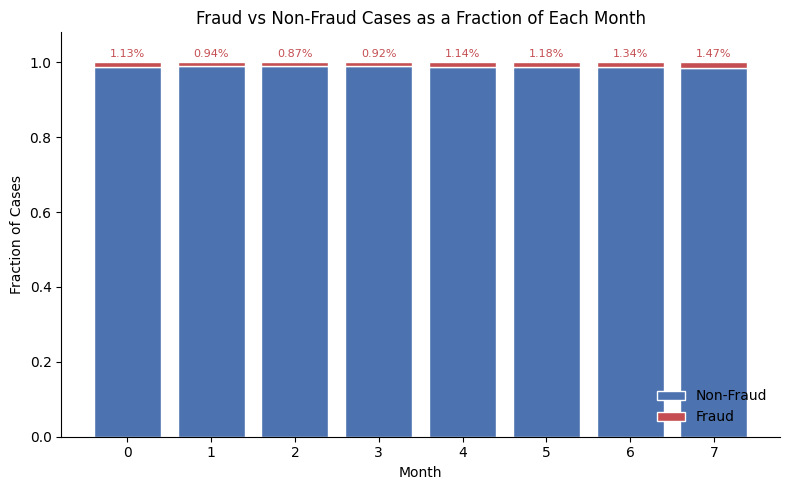

In [10]:
month_fraud = df.groupby('month')[target].value_counts(normalize=True).unstack()[[0, 1]]
month_fraud.columns = ['Non-Fraud', 'Fraud']

fig, ax = plot.subplots(figsize=(8, 5))

ax.bar(
    month_fraud.index, month_fraud['Non-Fraud'],
    color='#4C72B0', edgecolor='white', linewidth=1, label='Non-Fraud'
)
ax.bar(
    month_fraud.index, month_fraud['Fraud'], bottom=month_fraud['Non-Fraud'],
    color='#C44E52', edgecolor='white', linewidth=1, label='Fraud'
)

for month, frac in month_fraud['Fraud'].items():
    ax.text(month, 1.01, f'{frac:.2%}', ha='center', va='bottom', fontsize=8, color='#C44E52')

ax.set_xlabel('Month')
ax.set_ylabel('Fraction of Cases')
ax.set_title('Fraud vs Non-Fraud Cases as a Fraction of Each Month')
ax.set_xticks(month_fraud.index)
ax.set_ylim(0, 1.08)
ax.legend(loc='lower right', frameon=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plot.tight_layout()
plot.show()

- Fraud is rare at roughly 1% of applications in every month (heavy class imbalance).
- The rate dips in months 1-3 and climbs to 1.47% by month 7, so the data drifts over time. A time-based split (rather than a random one) gives a more realistic estimate of performance on future applications.

## Train Split

Each month has roughly 100-150k rows. Months 0-6 are used for training and month 7 is held out for validation (about a 7:1 split). All EDA below uses only the training months (`eda_df`), so nothing about the validation month informs feature decisions.

In [11]:
train_months = [0, 1, 2, 3, 4, 5, 6]

train_df = df[df["month"].isin(train_months)]
print(f"Train rows: {len(train_df):,} of {len(df):,}")

Train rows: 903,157 of 1,000,000


## Feature Distributions

Each feature's distribution is compared between fraud and non-fraud on the training months. Both classes are normalised (density / share within class), so the ~1% fraud class is visible on the same scale.

The helpers below choose a chart per feature: bar charts of within-class shares for categoricals and numeric features with 12 or fewer distinct values, and step histograms for everything else (log10 scale for heavily right-skewed features).

In [12]:
CLASS_COLORS = {0: '#2a78d6', 1: '#eb6834'}
CLASS_LABELS = {0: 'Non-Fraud', 1: 'Fraud'}
MAX_BAR_LEVELS = 12  # numeric features with this many distinct values or fewer get bar charts

eda_df = train_df.drop(columns=['month'])


def style_axis(ax, title, ylabel):
    ax.set_title(title, fontsize=10, loc='left')
    ax.set_ylabel(ylabel, fontsize=8, color='#52514e')
    ax.tick_params(labelsize=8, colors='#52514e')
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y', color='#e5e5e5', linewidth=0.8)
    ax.set_axisbelow(True)


def plot_histogram(ax, col, bins=40):
    values = eda_df[col].dropna()

    # Heavily right-skewed features are shown on a log10 scale so the bulk isn't one spike at zero
    shift = None
    if values.min() >= 0 and values.skew() > 2.5:
        shift = 0 if values.min() > 0 else 1
        values = np.log10(values + shift)

    # Trim the extreme 0.5% tails so outliers don't squash the rest of the distribution
    lo, hi = values.quantile([0.005, 0.995])
    if shift is None and (values % 1 == 0).all():
        # Integer-valued: align bins to whole numbers to avoid empty-bin comb artifacts
        step = max(1, int(np.ceil((hi - lo) / bins)))
        edges = np.arange(lo - 0.5, hi + step, step)
    else:
        edges = np.linspace(lo, hi, bins + 1)

    for cls in (0, 1):
        data = values[eda_df.loc[values.index, target] == cls]
        ax.hist(data[data.between(lo, hi)], bins=edges, density=True, histtype='step',
                linewidth=2, color=CLASS_COLORS[cls], label=CLASS_LABELS[cls])

    if shift is None:
        title = col
    elif shift == 0:
        title = f'log10({col})'
    else:
        title = f'log10(1 + {col})'
    style_axis(ax, title, 'Density')


def plot_bar_shares(ax, col):
    shares = (eda_df.groupby(target, observed=True)[col]
              .value_counts(normalize=True)
              .unstack(target)
              .fillna(0)
              .sort_index())
    x = np.arange(len(shares))
    width = 0.4
    for cls in (0, 1):
        # Non-fraud bars sit just left of each tick, fraud bars just right
        offset = (cls - 0.5) * width
        ax.bar(x + offset, shares[cls], width=width, color=CLASS_COLORS[cls],
               edgecolor='white', linewidth=2, label=CLASS_LABELS[cls])

    labels = []
    for level in shares.index:
        if isinstance(level, (int, float, np.number)):
            labels.append(f'{level:g}')
        else:
            labels.append(str(level))
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=45 if len(labels) > 6 else 0)
    style_axis(ax, col, 'Share within class')


def plot_feature_grid(cols, title, ncols=4):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plot.subplots(nrows, ncols, figsize=(max(4 * ncols, 10), 3 * nrows))
    axes = np.atleast_1d(axes).ravel()

    for ax, col in zip(axes, cols):
        if col in categorical_vars or eda_df[col].nunique() <= MAX_BAR_LEVELS:
            plot_bar_shares(ax, col)
        else:
            plot_histogram(ax, col)
    for ax in axes[len(cols):]:
        ax.set_visible(False)

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper right', ncol=2, frameon=False)
    fig.suptitle(title, x=0.01, ha='left', fontsize=13)
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    plot.show()


def plot_fraud_rate(ax, col, data=None):
    data = eda_df if data is None else data
    rates = data.groupby(col, observed=True)[target].agg(['mean', 'size'])
    base_rate = data[target].mean() * 100
    x = np.arange(len(rates))
    ax.bar(x, rates['mean'] * 100, width=0.6, color=CLASS_COLORS[1], edgecolor='white', linewidth=2)
    ax.axhline(base_rate, color='#52514e', linestyle='--', linewidth=1)

    # Labels sit above both the bar and the base-rate line so they don't collide
    for xi, rate, n in zip(x, rates['mean'], rates['size']):
        ax.text(xi, max(rate * 100, base_rate) * 1.04, f'{rate:.2%}\nn={n:,}',
                ha='center', va='bottom', fontsize=8, color='#52514e')

    ax.set_xticks(x)
    ax.set_xticklabels([f'{v:g}' for v in rates.index])
    ax.set_ylim(0, max(rates['mean'].max() * 100, base_rate) * 1.5)
    style_axis(ax, col, 'Fraud rate (%)')

### Columns to Remove

- `month` is excluded from `eda_df` above as it is used for the split, not as a feature.
- `device_fraud_count` is a constant 0 for every row, so it carries no information.
- `session_length_in_minutes_missing_flag` and `device_distinct_emails_8w_missing_flag` cover very few rows and their fraud rates sit close to the base rate.

The kept missing-value flags are plotted alongside for comparison.

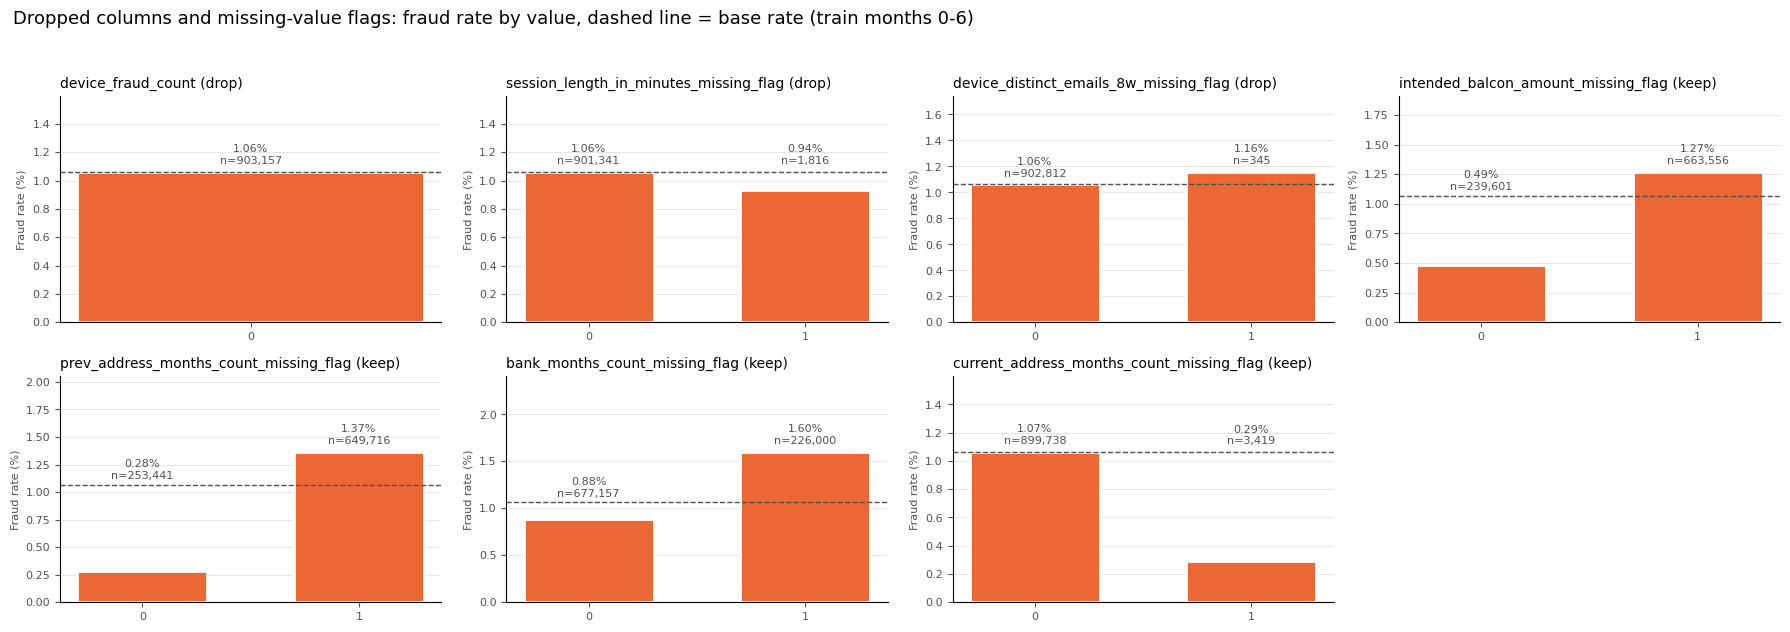

Base fraud rate (train): 1.06%


rows  fraud_rate_%
feature                                   value                      
device_fraud_count                        0      903157          1.06
session_length_in_minutes_missing_flag    0      901341          1.06
                                          1        1816          0.94
device_distinct_emails_8w_missing_flag    0      902812          1.06
                                          1         345          1.16
intended_balcon_amount_missing_flag       0      239601          0.49
                                          1      663556          1.27
prev_address_months_count_missing_flag    0      253441          0.28
                                          1      649716          1.37
bank_months_count_missing_flag            0      677157          0.88
                                          1      226000          1.60
current_address_months_count_missing_flag 0      899738          1.07
                                          1        3419          0.29

In [13]:
cols_to_drop = [
    'device_fraud_count',
    'session_length_in_minutes_missing_flag',
    'device_distinct_emails_8w_missing_flag',
]

# Plot every missing-value flag alongside the dropped columns, so the kept flags can be compared with the dropped ones
flag_cols = [col for col in eda_df.columns if col.endswith('_flag')]
plot_cols = cols_to_drop + [col for col in flag_cols if col not in cols_to_drop]

n_cols = 4
n_rows = int(np.ceil(len(plot_cols) / n_cols))
fig, axes = plot.subplots(n_rows, n_cols, figsize=(4.5 * n_cols, 3.2 * n_rows), squeeze=False)
for ax, col in zip(axes.flat, plot_cols):
    decision = 'drop' if col in cols_to_drop else 'keep'
    plot_fraud_rate(ax, col)
    ax.set_title(f'{col} ({decision})', fontsize=10, loc='left')
for ax in axes.flat[len(plot_cols):]:
    ax.set_visible(False)
fig.suptitle('Dropped columns and missing-value flags: fraud rate by value, dashed line = base rate (train months 0-6)',
             x=0.01, ha='left', fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plot.show()

print(f"Base fraud rate (train): {eda_df[target].mean():.2%}")
fraud_rate_by_value = {
    col: eda_df.groupby(col)[target].agg(rows='size', fraud_rate='mean')
    for col in plot_cols
}
drop_summary = pd.concat(fraud_rate_by_value, names=['feature', 'value'])
drop_summary['fraud_rate'] = (drop_summary['fraud_rate'] * 100).round(2)
drop_summary.rename(columns={'fraud_rate': 'fraud_rate_%'})

- The training base fraud rate is 1.06%.
- The three dropped columns sit at or near the base rate (the two flags differ by ~0.1pp on only 1,816 and 345 rows).
- The kept flags clearly separate the classes: missing `prev_address_months_count` (1.37% vs 0.28%), missing `intended_balcon_amount` (1.27% vs 0.49%) and missing `bank_months_count` (1.60% vs 0.88%) all carry signal.
- `current_address_months_count_missing_flag` covers only 3,419 rows but its fraud rate is well below base (0.29%), so it is kept.

### Kept Features

Every remaining feature is checked to belong to exactly one group, then each group is plotted as fraud vs non-fraud.

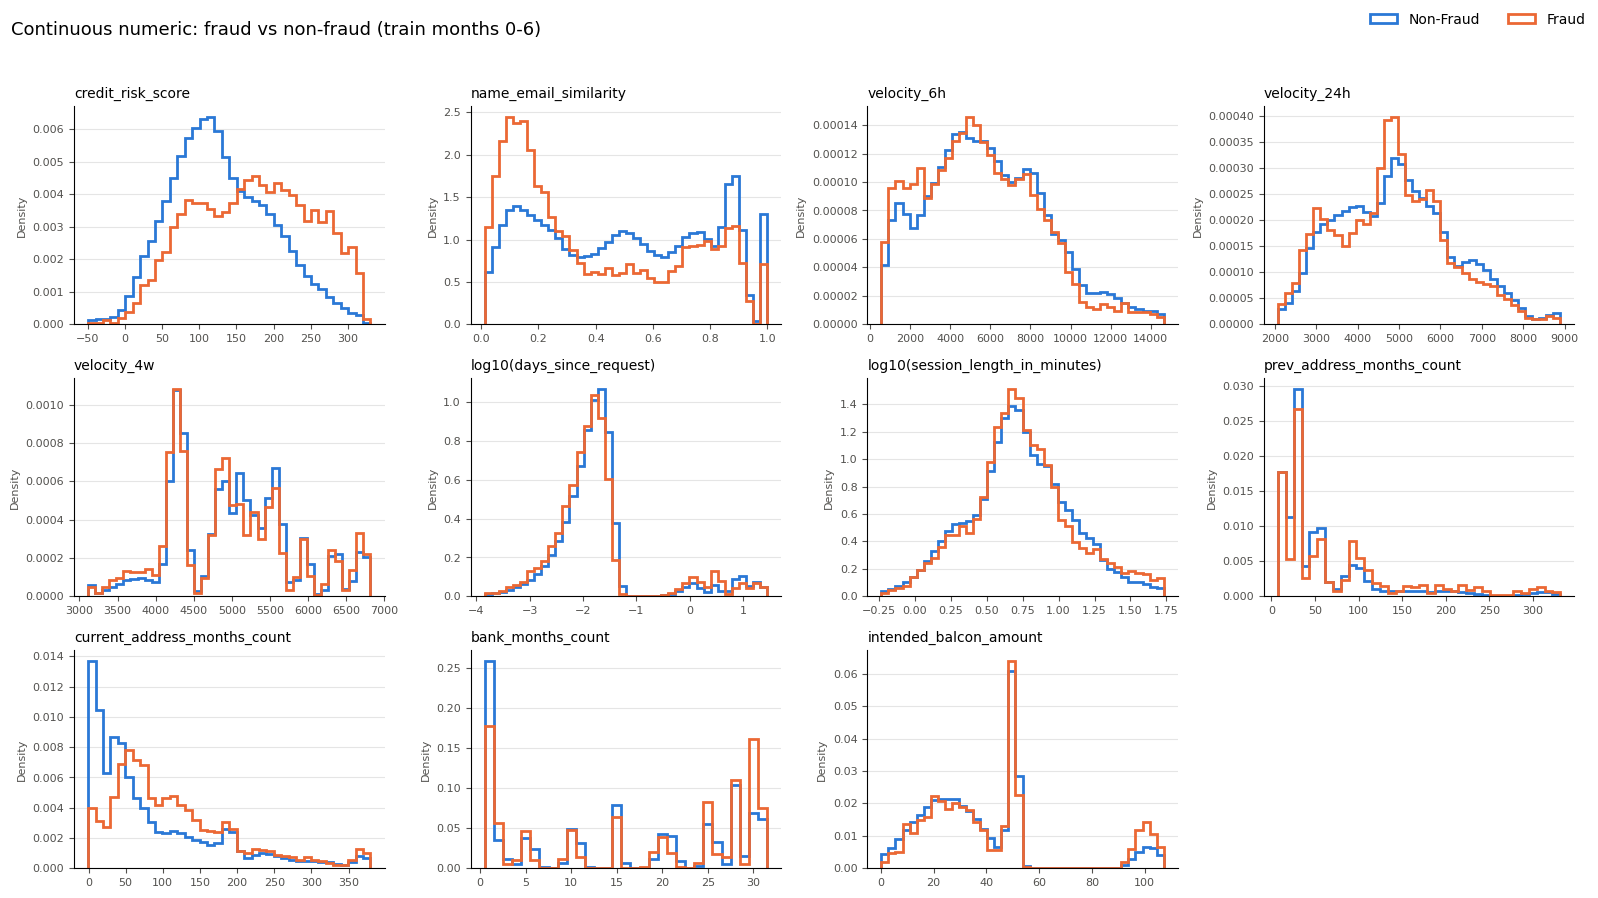

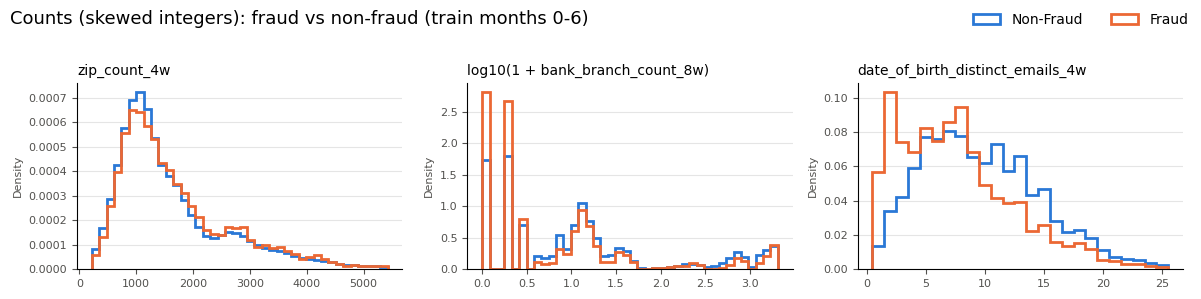

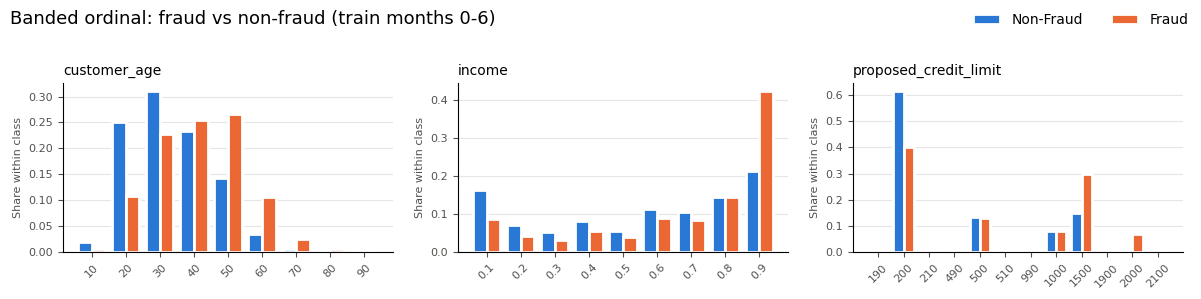

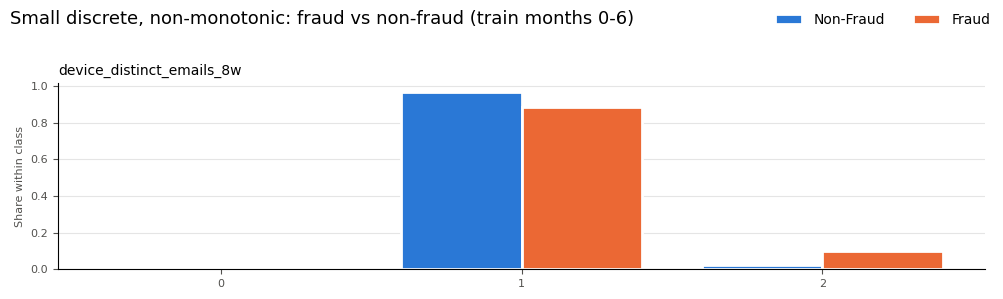

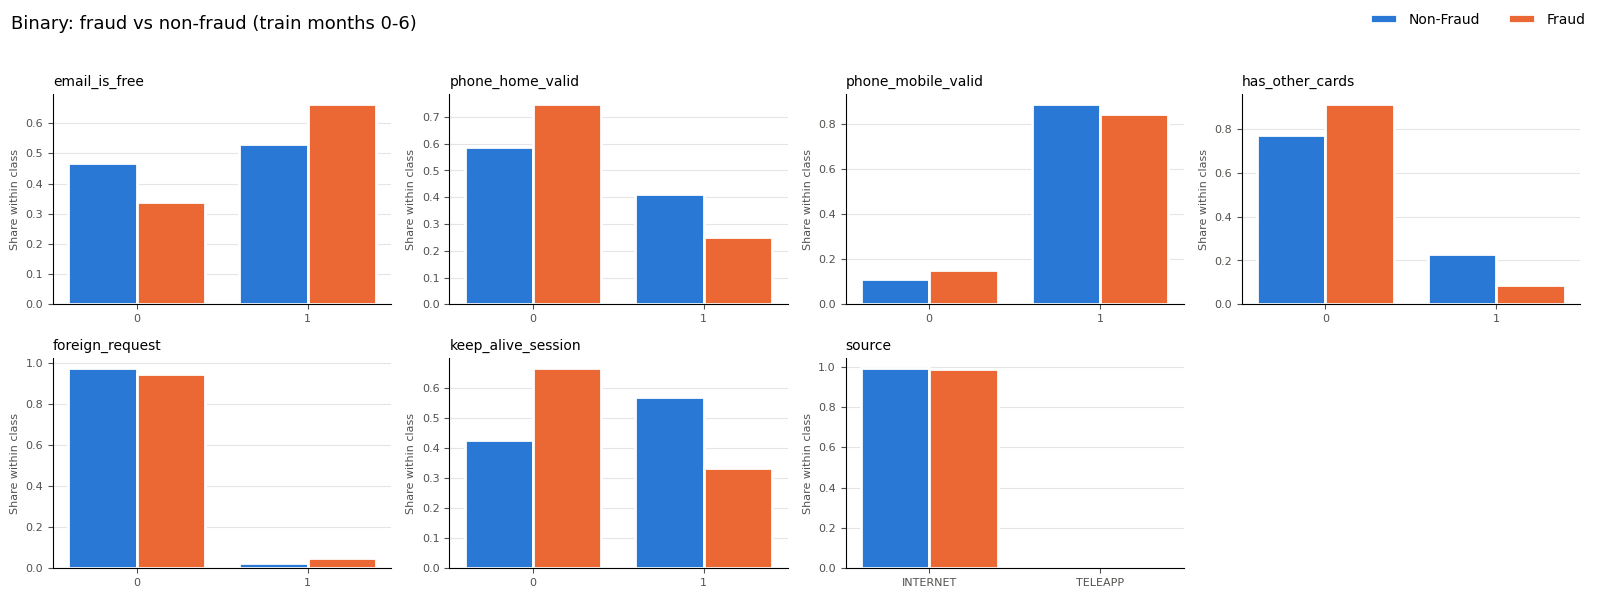

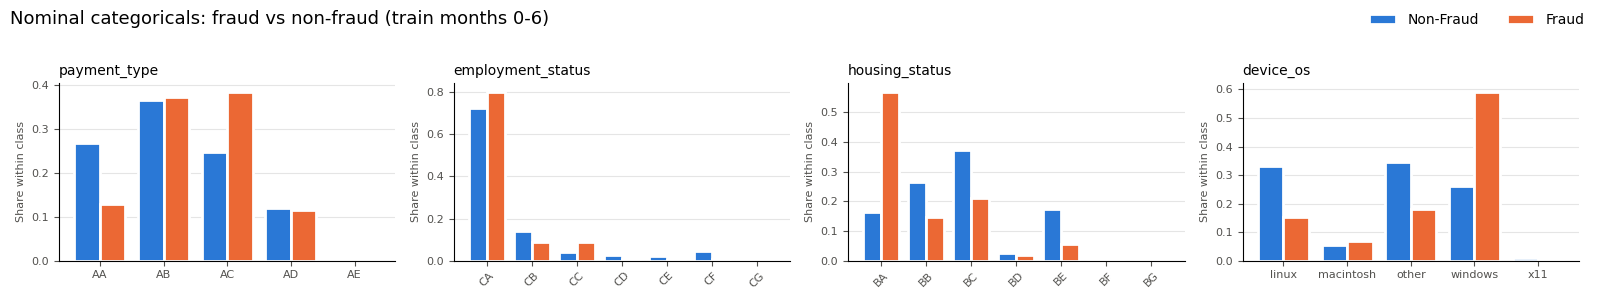

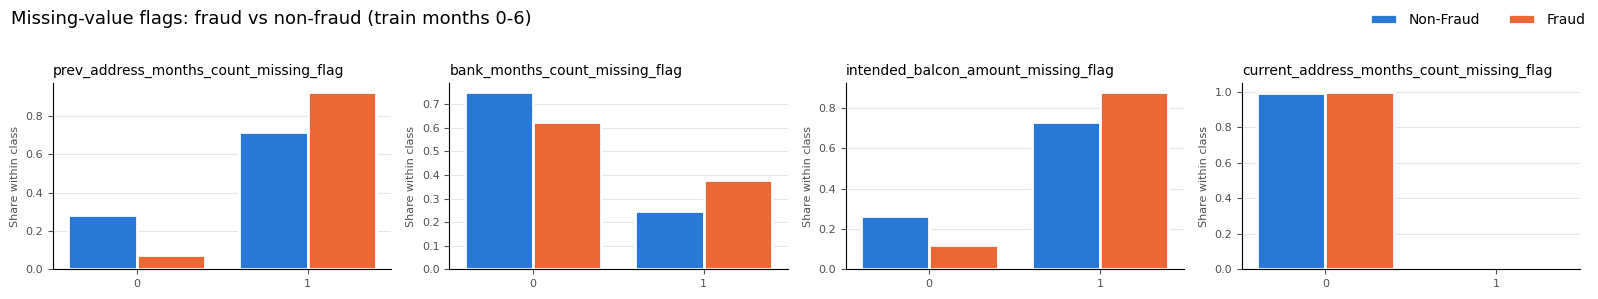

In [14]:
# Grouped by how each feature is treated in Feature Engineering
FEATURE_GROUPS = {
    'Continuous numeric': [
        'credit_risk_score', 'name_email_similarity', 'velocity_6h', 'velocity_24h', 'velocity_4w',
        'days_since_request', 'session_length_in_minutes', 'prev_address_months_count',
        'current_address_months_count', 'bank_months_count', 'intended_balcon_amount',
    ],
    'Counts (skewed integers)': ['zip_count_4w', 'bank_branch_count_8w', 'date_of_birth_distinct_emails_4w'],
    'Banded ordinal': ['customer_age', 'income', 'proposed_credit_limit'],
    'Small discrete, non-monotonic': ['device_distinct_emails_8w'],
    'Binary': [
        'email_is_free', 'phone_home_valid', 'phone_mobile_valid', 'has_other_cards',
        'foreign_request', 'keep_alive_session', 'source',
    ],
    'Nominal categoricals': ['payment_type', 'employment_status', 'housing_status', 'device_os'],
    'Missing-value flags': [
        'prev_address_months_count_missing_flag', 'bank_months_count_missing_flag',
        'intended_balcon_amount_missing_flag', 'current_address_months_count_missing_flag',
    ],
}

grouped_cols = []
for cols in FEATURE_GROUPS.values():
    grouped_cols.extend(cols)

# Every kept column must be in exactly one group; on failure, the message lists the columns that don't match
kept_cols = eda_df.columns.drop([target] + cols_to_drop)
assert sorted(grouped_cols) == sorted(kept_cols), set(grouped_cols) ^ set(kept_cols)

for group, cols in FEATURE_GROUPS.items():
    plot_feature_grid(cols, f'{group}: fraud vs non-fraud (train months 0-6)', ncols=min(4, len(cols)))

Observations by group:

- **Continuous numeric:** `credit_risk_score` is shifted higher for fraud, and `name_email_similarity` is much lower for fraud (names that don't match the email). `current_address_months_count` is lower for fraud. The `velocity_*`, `days_since_request` and `session_length_in_minutes` distributions largely overlap.
- **Counts:** `date_of_birth_distinct_emails_4w` is lower for fraud; `zip_count_4w` and `bank_branch_count_8w` show little difference.
- **Banded ordinal:** fraud skews older (40-60+) and towards the top `income` band (0.9). Fraud is much more common at `proposed_credit_limit` of 1,500 and above.
- **Small discrete:** `device_distinct_emails_8w = 2` is far more common among fraud. Levels 0 and 2 are both riskier than 1, so the relationship is not monotonic.
- **Binary:** fraud is more likely with a free email, no valid home phone, no other cards, a foreign request and no keep-alive session. `source` is almost entirely INTERNET for both classes.
- **Nominal categoricals:** `housing_status = BA`, `device_os = windows` and `payment_type = AC` are over-represented in fraud. Some levels are rare (e.g. `payment_type` AE, `housing_status` BF/BG) and may need merging.
- **Missing-value flags:** fraud is more likely when the previous address, bank months or balcon amount is missing, as shown above.